# 01 · Face recognition experiments

**Goal:** check how well SentryCare's face matcher separates *the same person* from *different people*, and
justify the decision threshold used by the live system.

**How recognition works (in short)**
1. **YuNet** finds each face and five landmarks (eyes, nose, mouth corners).
2. The face is **aligned** (rotated and cropped the same way every time).
3. **SFace** turns the aligned face into 128 numbers, a *face embedding*. Photos of the same person give similar embeddings.
4. Two embeddings are compared with **cosine similarity**: 1 means identical, around 0 means unrelated.
   A face is given a name only if its best match is **≥ 0.45** and at least **0.06** ahead of the next person.

**Privacy:** this notebook reads the locally enrolled profiles (`data/studio/`), which are **not in the repository**.
No face images are displayed and names are replaced with *Person A, B, …*. To reproduce, enrol people in the
SentryCare dashboard first (at least 3 photos each, with consent).

In [1]:
# --- Setup -------------------------------------------------------------------------------------
import itertools, json, string
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentrycare.paths import DATA_DIR
from sentrycare.registry import Registry
from sentrycare.vision import match_face

RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)
FIGURES = Path("../report/figures"); FIGURES.mkdir(parents=True, exist_ok=True)
THRESHOLD, MARGIN = 0.45, 0.06          # values used by the live system (sentrycare/vision.py)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

## 1. Enrolled data
Each profile holds the embeddings of its accepted photos. Only profiles with at least three photos are used for recognition.

In [2]:
# Load every enrolled profile's embeddings and replace real names with anonymous labels.
gallery = Registry(DATA_DIR / "studio").gallery()
assert gallery, "No enrolled profiles found. Enrol people in the dashboard first (3+ photos each)."
for label, person in zip(string.ascii_uppercase, sorted(gallery, key=lambda p: p["id"])):
    person["name"] = f"Person {label}"

summary = pd.DataFrame({"profile": [p["name"] for p in gallery],
                        "photos": [len(p["vectors"]) for p in gallery]})
print(f"{len(gallery)} profiles, {summary.photos.sum()} photos, embedding size = {len(gallery[0]['vectors'][0])}")
summary

5 profiles, 16 photos, embedding size = 128


,profile,photos
0,Person A,3
1,Person C,3
2,Person E,3
3,Person D,4
4,Person B,3


## 2. Same person vs different people

We compare every pair of photos:
- **Genuine pairs:** two photos of the *same* person. These should have **high** similarity.
- **Impostor pairs:** photos of two *different* people. These should have **low** similarity.

A good threshold sits in the gap between the two groups.

In [3]:
# Cosine similarity of normalised vectors is simply their dot product.
genuine, impostor = [], []
for p in gallery:
    genuine += [float(a @ b) for a, b in itertools.combinations(p["vectors"], 2)]
for p, q in itertools.combinations(gallery, 2):
    impostor += [float(a @ b) for a in p["vectors"] for b in q["vectors"]]
genuine, impostor = np.array(genuine), np.array(impostor)

stats = pd.DataFrame({"pairs": [len(genuine), len(impostor)],
                      "mean": [genuine.mean(), impostor.mean()],
                      "min": [genuine.min(), impostor.min()],
                      "max": [genuine.max(), impostor.max()]},
                     index=["genuine (same person)", "impostor (different people)"]).round(3)
stats

,pairs,mean,min,max
genuine (same person),18,0.624,0.490,0.844
impostor (different people),102,0.142,-0.088,0.379


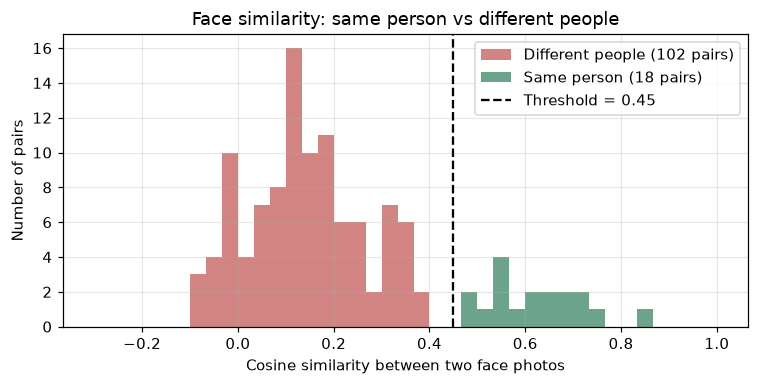

In [4]:
# Distribution plot with the live threshold marked.
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(-0.3, 1.0, 40)
ax.hist(impostor, bins=bins, alpha=.7, label=f"Different people ({len(impostor)} pairs)", color="#c0504d")
ax.hist(genuine, bins=bins, alpha=.7, label=f"Same person ({len(genuine)} pairs)", color="#2e7d5b")
ax.axvline(THRESHOLD, color="black", ls="--", lw=1.5, label=f"Threshold = {THRESHOLD}")
ax.set_xlabel("Cosine similarity between two face photos"); ax.set_ylabel("Number of pairs")
ax.set_title("Face similarity: same person vs different people"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "face_similarity.png", dpi=200); plt.show()

## 3. Experiment: recognising a held-out photo

**Closed-set identification (leave-one-out):** remove one photo from a profile, then ask the matcher who it is,
using everyone's remaining photos. Correct if the right name is returned.

**Unknown rejection:** remove the *whole* profile of the person in the photo. The matcher should now answer
**Unknown**, because that person is no longer enrolled. This simulates a stranger walking in.

In [5]:
def gallery_without(person_id, drop_index=None, drop_person=False):
    """Copy of the gallery with one photo, or one whole person, removed."""
    out = []
    for p in gallery:
        if p["id"] == person_id and drop_person:
            continue
        vectors = [v for i, v in enumerate(p["vectors"]) if not (p["id"] == person_id and i == drop_index)]
        out.append({**p, "vectors": vectors})
    return out

rows = []
for p in gallery:
    for i, vector in enumerate(p["vectors"]):
        known = match_face(vector, gallery_without(p["id"], drop_index=i), THRESHOLD, MARGIN)
        stranger = match_face(vector, gallery_without(p["id"], drop_person=True), THRESHOLD, MARGIN)
        rows.append({"profile": p["name"], "photo": i + 1,
                     "identified_as": known["name"], "correct": known["name"] == p["name"],
                     "score": known["similarity"],
                     "when_not_enrolled": stranger["name"], "rejected": stranger["name"] == "Unknown"})
loo = pd.DataFrame(rows)
print(f"Identification: {loo.correct.sum()}/{len(loo)} correct   |   "
      f"Unknown rejection: {loo.rejected.sum()}/{len(loo)} correctly rejected")
loo

Identification: 16/16 correct   |   Unknown rejection: 16/16 correctly rejected


,profile,photo,identified_as,correct,score,when_not_enrolled,rejected
0,Person A,1,Person A,True,0.635,Unknown,True
1,Person A,2,Person A,True,0.745,Unknown,True
2,Person A,3,Person A,True,0.734,Unknown,True
3,Person C,1,Person C,True,0.704,Unknown,True
4,Person C,2,Person C,True,0.703,Unknown,True
5,Person C,3,Person C,True,0.725,Unknown,True
6,Person E,1,Person E,True,0.591,Unknown,True
7,Person E,2,Person E,True,0.683,Unknown,True
8,Person E,3,Person E,True,0.651,Unknown,True
9,Person D,1,Person D,True,0.657,Unknown,True


## 4. Experiment: choosing the threshold

For each possible threshold we measure, over all photo pairs:
- **True accept rate (TAR):** share of *same-person* pairs accepted. Higher is better.
- **False accept rate (FAR):** share of *different-people* pairs wrongly accepted. Lower is better.

A safety system should keep FAR very low (a stranger must not be named as a resident) while keeping TAR high.

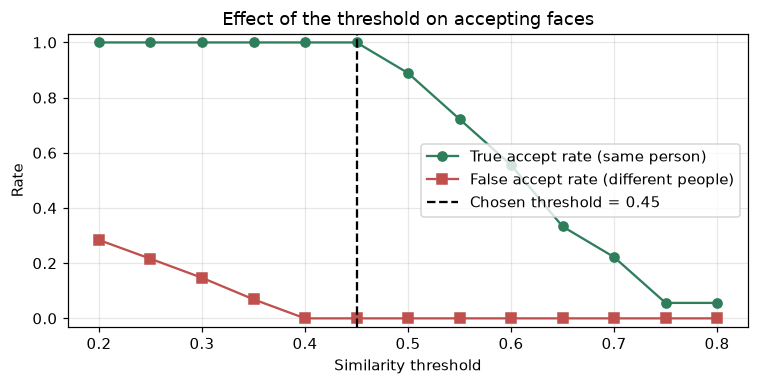

,threshold,TAR,FAR
0,0.20,1.000,0.284
1,0.25,1.000,0.216
2,0.30,1.000,0.147
3,0.35,1.000,0.069
4,0.40,1.000,0.000
5,0.45,1.000,0.000
6,0.50,0.889,0.000
7,0.55,0.722,0.000
8,0.60,0.556,0.000
9,0.65,0.333,0.000


In [6]:
thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
sweep = pd.DataFrame({"threshold": thresholds,
                      "TAR": [(genuine >= t).mean() for t in thresholds],
                      "FAR": [(impostor >= t).mean() for t in thresholds]}).round(3)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(sweep.threshold, sweep.TAR, "o-", color="#2e7d5b", label="True accept rate (same person)")
ax.plot(sweep.threshold, sweep.FAR, "s-", color="#c0504d", label="False accept rate (different people)")
ax.axvline(THRESHOLD, color="black", ls="--", lw=1.5, label=f"Chosen threshold = {THRESHOLD}")
ax.set_xlabel("Similarity threshold"); ax.set_ylabel("Rate"); ax.set_ylim(-0.03, 1.03)
ax.set_title("Effect of the threshold on accepting faces"); ax.legend(loc="center right")
fig.tight_layout(); fig.savefig(FIGURES / "face_threshold_sweep.png", dpi=200); plt.show()
sweep

## 5. Logged metrics
Aggregate numbers only (no names or embeddings) are saved to `results/face_metrics.json`.

In [7]:
at = sweep.set_index("threshold").loc[THRESHOLD]
metrics = {
    "profiles": len(gallery), "photos": int(summary.photos.sum()),
    "genuine_pairs": int(len(genuine)), "impostor_pairs": int(len(impostor)),
    "genuine_similarity_mean": round(float(genuine.mean()), 3),
    "impostor_similarity_mean": round(float(impostor.mean()), 3),
    "threshold": THRESHOLD, "margin": MARGIN,
    "TAR_at_threshold": float(at.TAR), "FAR_at_threshold": float(at.FAR),
    "leave_one_out_identification": f"{int(loo.correct.sum())}/{len(loo)}",
    "unknown_rejection": f"{int(loo.rejected.sum())}/{len(loo)}",
}
(RESULTS / "face_metrics.json").write_text(json.dumps(metrics, indent=2))
metrics

{'profiles': 5,
 'photos': 16,
 'genuine_pairs': 18,
 'impostor_pairs': 102,
 'genuine_similarity_mean': 0.624,
 'impostor_similarity_mean': 0.142,
 'threshold': 0.45,
 'margin': 0.06,
 'TAR_at_threshold': 1.0,
 'FAR_at_threshold': 0.0,
 'leave_one_out_identification': '16/16',
 'unknown_rejection': '16/16'}

## Conclusion

- Same-person photos score clearly higher than different-people photos, and the 0.45 threshold sits in the gap.
- With the margin rule and two-check confirmation used live, a stranger is very unlikely to be named as a resident.

**Limitations:** this is a small set of locally enrolled profiles. A proper benchmark needs many more consenting
people, new photos taken on different days and in different lighting, and spoofing tests (a printed photo or a screen).